In [32]:
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

In [2]:
df = pd.read_csv('Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.shape

(7043, 21)

In [8]:
df.duplicated().sum()

np.int64(0)

In [12]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['str']).columns.tolist()

print(numerical_cols)
print(categorical_cols)

['SeniorCitizen', 'tenure', 'MonthlyCharges']
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [14]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [15]:
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']

df[binary_cols] = df[binary_cols].replace({
    'Yes': 1,
    'No': 0
})

In [16]:
df[binary_cols].head()

,Partner,Dependents,PhoneService,PaperlessBilling
0,1,0,0,1
1,0,0,1,0
2,0,0,1,1
3,0,0,0,0
4,0,0,1,1


In [17]:
df[binary_cols].dtypes

Partner             object
Dependents          object
PhoneService        object
PaperlessBilling    object
dtype: object

In [18]:
df[binary_cols] = df[binary_cols].astype('int64')

In [19]:
df[binary_cols].dtypes

Partner             int64
Dependents          int64
PhoneService        int64
PaperlessBilling    int64
dtype: object

In [26]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()

In [27]:
df[numerical_cols].describe()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,0.483033,0.299588,32.371149,0.903166,0.592219,64.761692
std,0.368612,0.499748,0.458110,24.559481,0.295752,0.491457,30.090047
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.250000
25%,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,35.500000
50%,0.000000,0.000000,0.000000,29.000000,1.000000,1.000000,70.350000
75%,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,89.850000
max,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,118.750000


In [23]:
categorical_cols = df.select_dtypes(include=['str']).columns.tolist()

In [20]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [21]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [24]:
for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

customerID: <StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
MultipleLines: <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService: <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup: <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dt

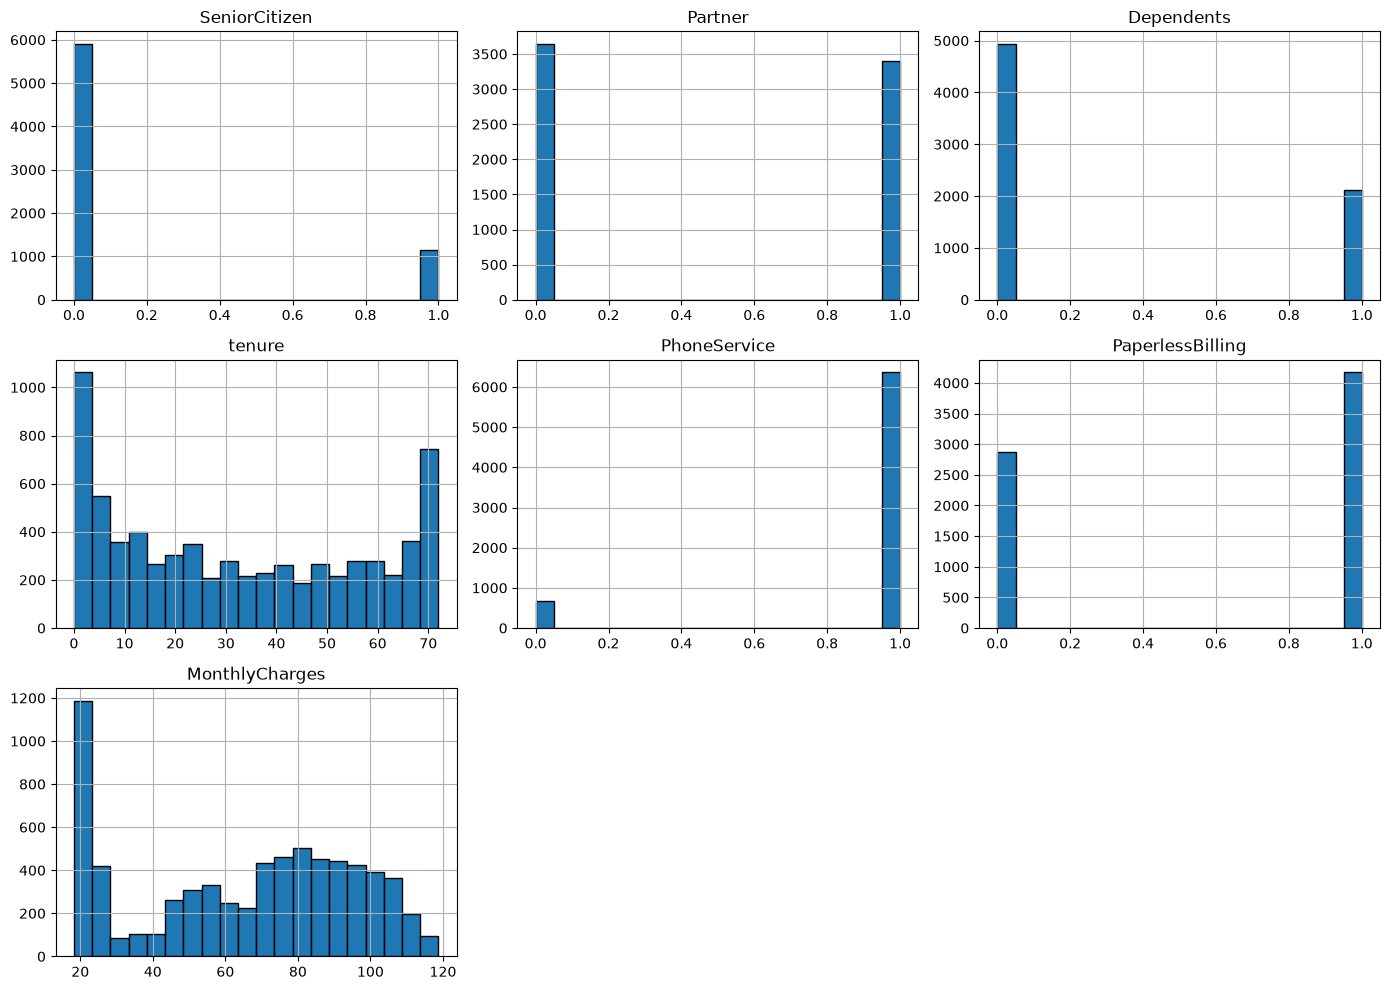

In [33]:
df[numerical_cols].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.gcf().tight_layout()
plt.show()

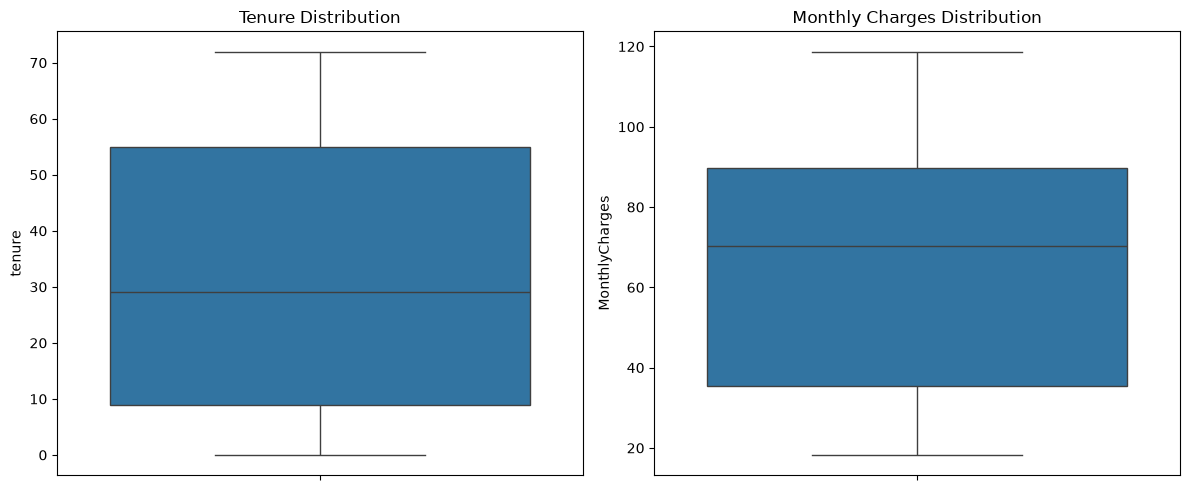

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['tenure'], ax=axes[0])
axes[0].set_title('Tenure Distribution')

sns.boxplot(y=df['MonthlyCharges'], ax=axes[1])
axes[1].set_title('Monthly Charges Distribution')

plt.tight_layout()
plt.show()

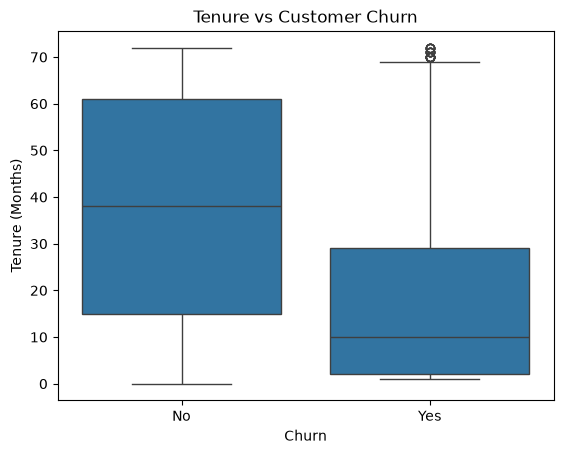

In [35]:
sns.boxplot(data=df, x='Churn', y='tenure')

plt.title('Tenure vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')
plt.show()

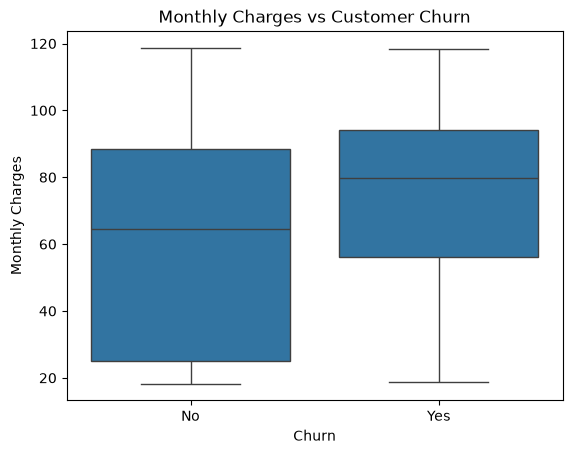

In [36]:
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

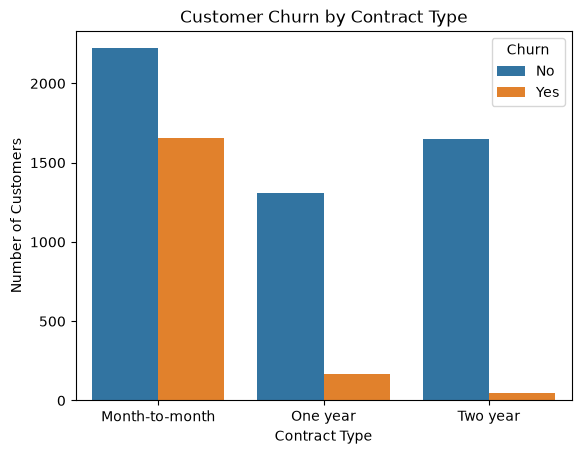

In [37]:
sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

In [38]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [39]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


In [40]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


In [41]:
# Columns we want to analyze
categorical_features = [
    'gender',
    'SeniorCitizen',
    'Partner',
    'Dependents',
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'PaperlessBilling'
]

# Calculate churn percentages for every feature
for col in categorical_features:

    churn_rate = pd.crosstab(
        df[col],
        df['Churn'],
        normalize='index'
    ) * 100

    print(f"\n{'='*50}")
    print(f"Churn rate by {col}")
    print('='*50)

    print(churn_rate.round(2))


Churn rate by gender
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

Churn rate by SeniorCitizen
Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68

Churn rate by Partner
Churn       No    Yes
Partner              
0        67.04  32.96
1        80.34  19.66

Churn rate by Dependents
Churn          No    Yes
Dependents              
0           68.72  31.28
1           84.55  15.45

Churn rate by PhoneService
Churn            No    Yes
PhoneService              
0             75.07  24.93
1             73.29  26.71

Churn rate by MultipleLines
Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61

Churn rate by OnlineSecurity
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14

In [42]:
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].unique()[:15])

str
<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',  '587.45',   '326.8',  '5681.1',  '5036.3',
 '2686.05']
Length: 15, dtype: str


In [43]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].str.strip(),
    errors='coerce'
)

print(df['TotalCharges'].isnull().sum())

11


In [44]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,1,1,0,0,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,1,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,0,1,0,1,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,0,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,1,1,0,1,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,0,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,1,1,0,1,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,0,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,1,1,0,0,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,0,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,1,1,0,1,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,0,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,1,1,0,1,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,0,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,1,1,0,1,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,0,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,1,1,0,1,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,1,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,1,1,0,1,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,0,Mailed check,73.35,NaN,No


In [45]:
df.loc[df['TotalCharges'].isnull(), ['tenure', 'MonthlyCharges', 'TotalCharges']]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [46]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [47]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [48]:
numerical_cols = df.select_dtypes(include='number').columns.tolist()

In [49]:
df['Churn_encoded'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

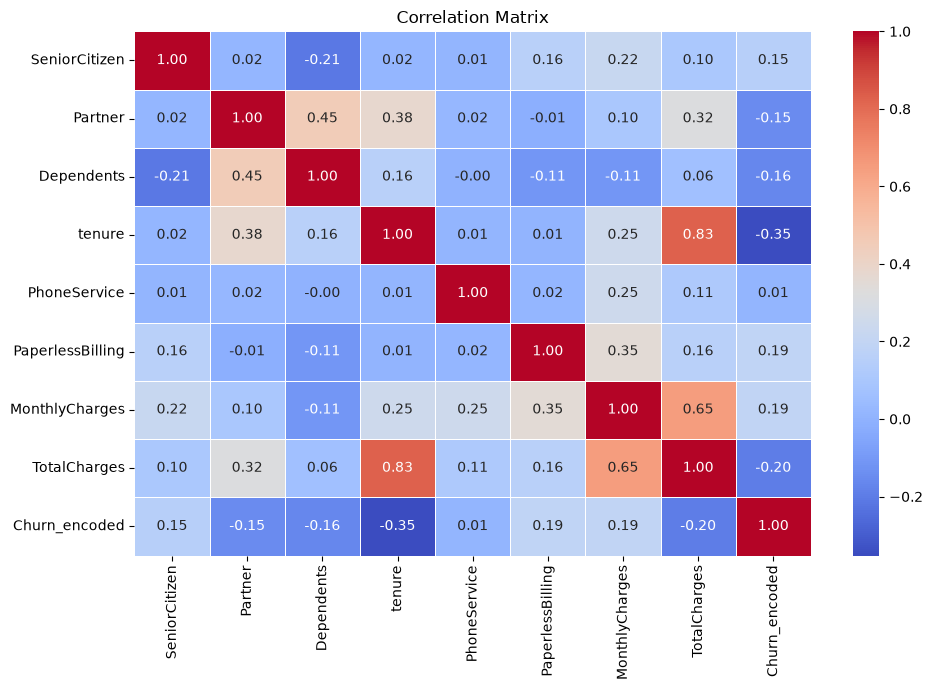

In [50]:
corr = df[numerical_cols + ['Churn_encoded']].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [52]:
# Encode the target variable
df['Churn_encoded'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

# Select numerical columns
numerical_cols = df.select_dtypes(include='number').columns.tolist()

# Calculate correlation with Churn
churn_corr = df[numerical_cols].corr()['Churn_encoded']

# Remove correlation with itself and sort
churn_corr = churn_corr.drop('Churn_encoded').sort_values(
    ascending=False
)

print(churn_corr)

MonthlyCharges      0.193356
PaperlessBilling    0.191825
SeniorCitizen       0.150889
PhoneService        0.011942
Partner            -0.150448
Dependents         -0.164221
TotalCharges       -0.198324
tenure             -0.352229
Name: Churn_encoded, dtype: float64


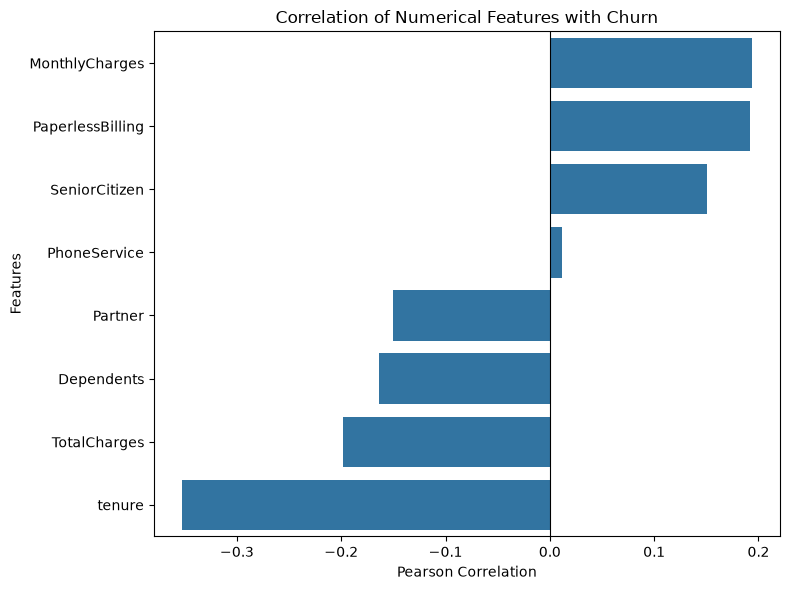

In [53]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=churn_corr.values,
    y=churn_corr.index
)

plt.title('Correlation of Numerical Features with Churn')
plt.xlabel('Pearson Correlation')
plt.ylabel('Features')
plt.axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()